# 06 · Failure investigation and reliability

Real MetroPT-3 data. Run `python -m src.pipeline --csv data/raw/MetroPT3.csv` first to regenerate the analysis inputs. These notebooks also run directly on the aggregated outputs included in the delivery.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import ANALOG, DIGITAL
OUT = ROOT / 'data/processed'
x = pd.read_parquet(OUT / 'monitoring_5min.parquet')
events = pd.read_csv(ROOT / 'data/reference/failure_events.csv', parse_dates=['start','end'])
quality = json.loads((ROOT / 'reports/data_quality.json').read_text())
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 30)


## Investigation design
Compare each reported event with the preceding seven days, excluding other documented events and low-quality bins. Hourly means are the resampling unit for descriptive bootstrap intervals. Results are associations, not confirmed causes. Actual downtime and repair duration are not present.

,event_id,sensor,baseline_hours,event_hours,baseline_mean,event_mean,difference,bootstrap_low,bootstrap_high,welch_p,fdr_p
0,E01,TP2,128,24,1.624977,8.608012,6.983035,6.557494,7.374977,5.092891e-62,2.037157e-61
1,E01,TP3,128,24,9.061127,8.815618,-0.245510,-0.291169,-0.201232,2.171697e-18,4.343395e-18
2,E01,H1,128,24,7.370353,-0.007459,-7.377812,-7.757006,-6.948142,2.322679e-65,1.083917e-64
3,E01,DV_pressure,128,24,0.154827,1.899733,1.744906,1.655071,1.822822,2.321909e-74,1.300269e-73
4,E01,Reservoirs,128,24,9.061274,8.816709,-0.244565,-0.291074,-0.199110,2.550537e-18,4.761003e-18
5,E01,Oil_temperature,128,24,58.055886,74.377310,16.321424,15.140303,17.501013,3.559296e-60,1.245754e-59
6,E01,Motor_current,128,24,1.993609,5.663891,3.670282,3.435536,3.896861,1.532498e-58,4.290995e-58
7,E02,TP2,96,8,1.471976,7.616635,6.144659,4.882082,6.865155,2.137887e-05,3.521226e-05
8,E02,TP3,96,8,8.972058,8.564572,-0.407485,-0.634517,-0.026156,5.282222e-02,6.020840e-02
9,E02,H1,96,8,7.477480,0.774422,-6.703058,-7.617644,-5.065383,5.211973e-05,8.107514e-05


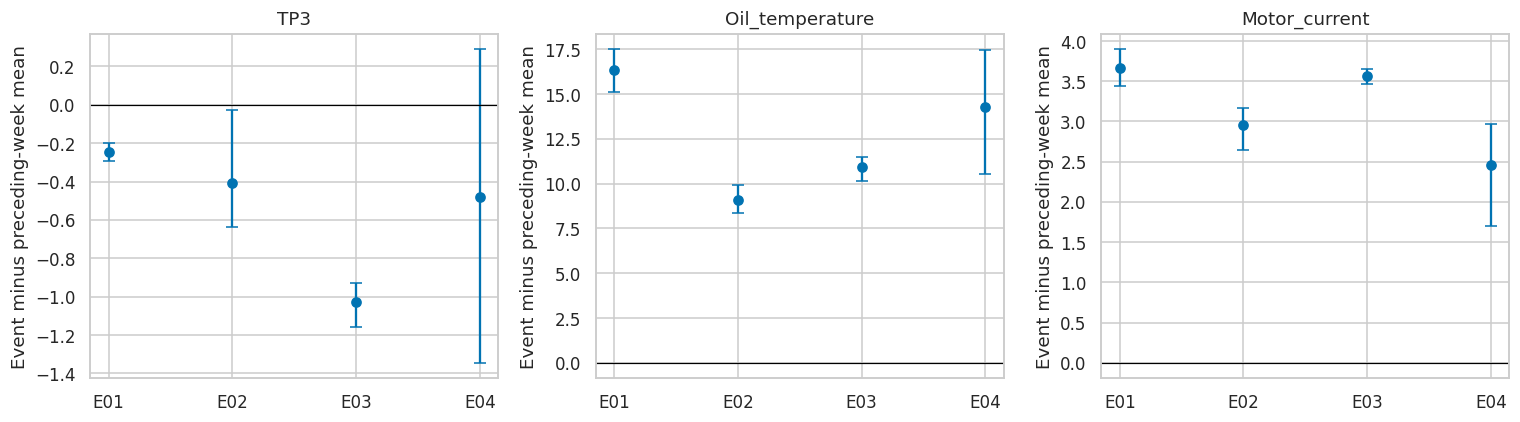

In [2]:
comparison=pd.read_csv(OUT/'event_sensor_comparison.csv')
display(comparison)
fig,axs=plt.subplots(1,3,figsize=(14,4))
for ax,c in zip(axs,['TP3','Oil_temperature','Motor_current']):
    d=comparison.loc[comparison.sensor.eq(c)].set_index('event_id')
    ax.errorbar(d.index,d.difference,yerr=[d.difference-d.bootstrap_low,d.bootstrap_high-d.difference],fmt='o',capsize=4)
    ax.axhline(0,color='black',lw=.8); ax.set(title=c,ylabel='Event minus preceding-week mean')
plt.tight_layout(); plt.show()


Bootstrap intervals do not remove seasonal or operating-state confounding. Hourly blocks can remain correlated. Welch p-values are exploratory, with Benjamini–Hochberg correction across sensor/event comparisons. Effect size and operating context matter more than a small p-value.

In [3]:
# State-conditioned context: compare predominantly loaded bins separately.
rows=[]
for e in events.itertuples():
    state=x.quality_eligible & x.load_fraction.ge(.9)
    before=state & (x.index>=e.start-pd.Timedelta('7d')) & (x.index<e.start) & ~x.event_window
    during=state & (x.index>e.start) & (x.index<=e.end)
    rows.append({'event':e.event_id,'baseline_loaded_bins':int(before.sum()),'event_loaded_bins':int(during.sum()),'baseline_pressure':x.loc[before,'TP3'].mean(),'event_pressure':x.loc[during,'TP3'].mean(),'baseline_current':x.loc[before,'Motor_current'].mean(),'event_current':x.loc[during,'Motor_current'].mean()})
display(pd.DataFrame(rows))


,event,baseline_loaded_bins,event_loaded_bins,baseline_pressure,event_pressure,baseline_current,event_current
0,E01,145,282,9.394736,8.818185,5.796218,5.663543
1,E02,16,77,8.137489,8.384351,5.670760,5.579725
2,E03,37,571,8.462046,8.022308,4.209585,5.494038
3,E04,36,51,7.053626,8.176546,3.968971,5.567311


In [4]:
event_eval=pd.read_csv(OUT/'event_evaluation.csv')
display(event_eval)
display(event_eval.pivot(index='event_id',columns='model',values='detected_during_event'))
display(event_eval.pivot(index='event_id',columns='model',values='lead_hours'))


,model,event_id,observed,eligible_event_bins,alert_bins,detected_during_event,first_event_alert,warning_in_previous_24h,first_warning,lead_hours
0,zscore,E01,True,283,281,True,2020-04-18 00:40:00,False,NaT,NaN
1,zscore,E02,True,79,77,True,2020-05-29 23:35:00,True,2020-05-29 23:25:00,0.083333
2,zscore,E03,True,571,567,True,2020-06-05 10:05:00,True,2020-06-05 10:00:00,0.000000
3,zscore,E04,True,54,0,False,NaT,False,NaT,NaN
4,rolling_z,E01,True,283,0,False,NaT,False,NaT,NaN
5,rolling_z,E02,True,79,0,False,NaT,False,NaT,NaN
6,rolling_z,E03,True,571,0,False,NaT,False,NaT,NaN
7,rolling_z,E04,True,54,0,False,NaT,False,NaT,NaN
8,cusum,E01,True,283,281,True,2020-04-18 00:40:00,False,NaT,NaN
9,cusum,E02,True,79,77,True,2020-05-29 23:35:00,True,2020-05-29 23:25:00,0.083333


model,cusum,isolation_forest,mahalanobis,rolling_z,threshold,zscore
event_id,,,,,,
E01,True,False,True,False,True,True
E02,True,False,True,False,True,True
E03,True,True,True,False,True,True
E04,False,False,False,False,False,False


model,cusum,isolation_forest,mahalanobis,rolling_z,threshold,zscore
event_id,,,,,,
E01,NaN,NaN,NaN,NaN,NaN,NaN
E02,0.083333,NaN,0.083333,NaN,0.083333,0.083333
E03,0.000000,NaN,0.000000,NaN,0.000000,0.000000
E04,NaN,NaN,NaN,NaN,NaN,NaN


An alert before the recorded start is a candidate warning, not proof of prediction. Compare any lead-time claim with its detector’s background alert burden. Alerts after the start only count as in-event detection. No event without eligible observations is silently counted as a miss.

In [5]:
duration=events[['event_id','start','end']].copy()
duration['reported_interval_hours']=(duration.end-duration.start).dt.total_seconds()/3600
duration['elapsed_hours_between_starts']=duration.start.diff().dt.total_seconds()/3600
display(duration)
display(Markdown(f'Total reported interval exposure: **{duration.reported_interval_hours.sum():.2f} hours**. This is not downtime, MTTR or service interruption.'))


,event_id,start,end,reported_interval_hours,elapsed_hours_between_starts
0,E01,2020-04-18 00:00:00,2020-04-18 23:59:00,23.983333,NaN
1,E02,2020-05-29 23:30:00,2020-05-30 06:00:00,6.500000,1007.5
2,E03,2020-06-05 10:00:00,2020-06-07 14:30:00,52.500000,154.5
3,E04,2020-07-15 14:30:00,2020-07-15 19:00:00,4.500000,964.5


Total reported interval exposure: **87.48 hours**. This is not downtime, MTTR or service interruption.

## Engineering handoff
1. Inspect pressure/current/load patterns around each event with maintenance staff.
2. Investigate simultaneous flatline episodes with the logger team.
3. Obtain verified maintenance start/end times and operating hours.
4. Label alert episodes in a shadow-mode pilot to measure confirmed false alarms.
5. Validate on another compressor before generalising.

MTBF, MTTR, RUL and availability as an equipment-reliability measure remain unsupported. The delivered report contains measured monitoring coverage and reported-event exposure instead.